threads: 6
GPU: NVIDIA GeForce RTX 3070 Ti (7.7 GB)


/tmp/ipykernel_2827030/3076987502.py:32: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(f, encoding='latin1')


train: (50000, 3, 32, 32)   test: (10000, 3, 32, 32)


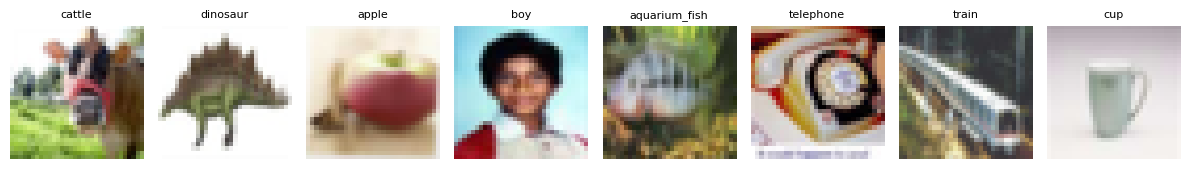

In [1]:
#N1: imports + threads + load CIFAR-100 (pickled files: meta, train, test), kept in colour

import os
N_THREADS = 6                                    # Baby-U: 12 cores, the GPU does the training (6 leaves room for a 2nd notebook)
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)   # must be set BEFORE importing torch/numpy
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)

import pickle, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(N_THREADS)                 # PyTorch uses only these cores
print("threads:", torch.get_num_threads())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")
    torch.backends.cuda.matmul.allow_tf32 = True     # RTX 30xx: faster float32 matrix products, same results to ~3 digits
    torch.backends.cudnn.allow_tf32 = True
else:
    print("no GPU found: running on the CPU (much slower)")

CPU_SLOT = 1     # only used on the 64-core Fatbaby: 0 -> cores 0-15, 1 -> 16-31, ... (Baby-U skips this)
if (os.cpu_count() or 0) >= 64:
    os.sched_setaffinity(0, range(16 * CPU_SLOT, 16 * CPU_SLOT + 16))
    print(f"pinned to cores {16 * CPU_SLOT}-{16 * CPU_SLOT + 15}")

BASE = '/home/worker/Scaricati/cifar'   # CHANGE to the folder on Baby-U that holds meta, train, test

def unpickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='latin1')

meta  = unpickle(os.path.join(BASE, 'meta'))
train = unpickle(os.path.join(BASE, 'train'))
test  = unpickle(os.path.join(BASE, 'test'))
fine_names = meta['fine_label_names']            # 100 names, index = fine label

# each row = 1024 red + 1024 green + 1024 blue values -> keep colour: [N, 3, 32, 32] (no grayscale, no resizing)
x_train_all = np.asarray(train['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_train_all = np.array(train['fine_labels'])
x_test_all  = np.asarray(test['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_test_all  = np.array(test['fine_labels'])
print(f"train: {x_train_all.shape}   test: {x_test_all.shape}")

fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for k in range(8):
    axes[k].imshow(x_train_all[k].transpose(1, 2, 0))
    axes[k].set_title(fine_names[y_train_all[k]], fontsize=8)
    axes[k].axis('off')
plt.tight_layout(); plt.show()

In [2]:
import sys, os, subprocess, torch
print("python used by this notebook:", sys.executable)
print("torch version:", torch.__version__, "| built for CUDA:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("CUDA_VISIBLE_DEVICES =", os.environ.get("CUDA_VISIBLE_DEVICES"))
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi not found -> NVIDIA driver not installed (or not on PATH)")

python used by this notebook: /opt/miniconda3/bin/python
torch version: 2.8.0+cu128 | built for CUDA: 12.8
cuda available: True
CUDA_VISIBLE_DEVICES = None
Mon Nov 16 02:16:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.71.10              KMD Version: 615.71.10     CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3070 Ti     On  |   00000000:65:00.0 Off |                  N/A |
|  0%   34C    P8             25W /  290W |       4MiB /   8192MiB |      0%

In [3]:
#N2: defining 20 problems: the 20 CIFAR-100 superclasses, 5 fine classes each (same as the earlier MLP and ViT notebooks)

SCRIPT_NAMES = ["P1_aquatic", "P2_fish", "P3_flowers", "P4_containers", "P5_produce",
                "P6_devices", "P7_furniture", "P8_insects", "P9_carnivores", "P10_outdoor_things",
                "P11_outdoor_scenes", "P12_omni_herbivores", "P13_medium_mammals", "P14_invertebrates", "P15_people",
                "P16_reptiles", "P17_small_mammals", "P18_trees", "P19_vehicles_1", "P20_vehicles_2"]

GROUP_CLASS_NAMES = [
    ["beaver", "dolphin", "otter", "seal", "whale"],                     # P1
    ["aquarium_fish", "flatfish", "ray", "shark", "trout"],              # P2
    ["orchid", "poppy", "rose", "sunflower", "tulip"],                   # P3
    ["bottle", "bowl", "can", "cup", "plate"],                           # P4
    ["apple", "mushroom", "orange", "pear", "sweet_pepper"],             # P5
    ["clock", "keyboard", "lamp", "telephone", "television"],            # P6
    ["bed", "chair", "couch", "table", "wardrobe"],                      # P7
    ["bee", "beetle", "butterfly", "caterpillar", "cockroach"],          # P8
    ["bear", "leopard", "lion", "tiger", "wolf"],                        # P9
    ["bridge", "castle", "house", "road", "skyscraper"],                 # P10
    ["cloud", "forest", "mountain", "plain", "sea"],                     # P11
    ["camel", "cattle", "chimpanzee", "elephant", "kangaroo"],           # P12
    ["fox", "porcupine", "possum", "raccoon", "skunk"],                  # P13
    ["crab", "lobster", "snail", "spider", "worm"],                      # P14
    ["baby", "boy", "girl", "man", "woman"],                             # P15
    ["crocodile", "dinosaur", "lizard", "snake", "turtle"],              # P16
    ["hamster", "mouse", "rabbit", "shrew", "squirrel"],                 # P17
    ["maple_tree", "oak_tree", "palm_tree", "pine_tree", "willow_tree"], # P18
    ["bicycle", "bus", "motorcycle", "pickup_truck", "train"],           # P19
    ["lawn_mower", "rocket", "streetcar", "tank", "tractor"],            # P20
]

name_to_fine = {n: i for i, n in enumerate(fine_names)}
GROUP_LABELS = [[name_to_fine[n] for n in grp] for grp in GROUP_CLASS_NAMES]
for name, names, labels in zip(SCRIPT_NAMES, GROUP_CLASS_NAMES, GROUP_LABELS):
    print(f"{name:20s}", list(zip(names, labels)))
print("\n20 problems, 5 classes each, all 100 CIFAR-100 fine classes used")

P1_aquatic           [('beaver', 4), ('dolphin', 30), ('otter', 55), ('seal', 72), ('whale', 95)]
P2_fish              [('aquarium_fish', 1), ('flatfish', 32), ('ray', 67), ('shark', 73), ('trout', 91)]
P3_flowers           [('orchid', 54), ('poppy', 62), ('rose', 70), ('sunflower', 82), ('tulip', 92)]
P4_containers        [('bottle', 9), ('bowl', 10), ('can', 16), ('cup', 28), ('plate', 61)]
P5_produce           [('apple', 0), ('mushroom', 51), ('orange', 53), ('pear', 57), ('sweet_pepper', 83)]
P6_devices           [('clock', 22), ('keyboard', 39), ('lamp', 40), ('telephone', 86), ('television', 87)]
P7_furniture         [('bed', 5), ('chair', 20), ('couch', 25), ('table', 84), ('wardrobe', 94)]
P8_insects           [('bee', 6), ('beetle', 7), ('butterfly', 14), ('caterpillar', 18), ('cockroach', 24)]
P9_carnivores        [('bear', 3), ('leopard', 42), ('lion', 43), ('tiger', 88), ('wolf', 97)]
P10_outdoor_things   [('bridge', 12), ('castle', 17), ('house', 37), ('road', 68), ('skysc

In [4]:
#N3: building 20 datasets: colour 3x32x32, standardized per problem and per colour channel
#    every problem has THREE sets of images:
#      training images  2,250 (450 per class)  the network learns from these
#      validation images  250 (50 per class, taken from the 500 training images of each class)
#                             -> early stopping: when to stop a run; the network never learns from them
#      test images        500 (100 per class)  tested once per run, with its best weights (N6); never for a decision

VAL_PER_CLASS = 50

rng = np.random.default_rng(0)    # fixed: the same validation images as the TUNING = True runs of the earlier notebooks
X_tr, Y_tr, X_val, Y_val, X_te, Y_te = [], [], [], [], [], []
for m in range(20):
    xs_tr, ys_tr, xs_val, ys_val, xs_te, ys_te = [], [], [], [], [], []
    for new_label, old_label in enumerate(GROUP_LABELS[m]):          # labels 0-4 = position in the group list
        tr = x_train_all[y_train_all == old_label]                   # 500 training images of this class
        te = x_test_all[y_test_all == old_label]                     # 100 test images of this class
        perm = rng.permutation(len(tr))
        va, tr = tr[perm[:VAL_PER_CLASS]], tr[perm[VAL_PER_CLASS:]]   # 50 validation, 450 to learn from
        xs_tr.append(tr); ys_tr.append(np.full(len(tr), new_label))
        xs_val.append(va); ys_val.append(np.full(len(va), new_label))
        xs_te.append(te); ys_te.append(np.full(len(te), new_label))
    x_tr = torch.tensor(np.concatenate(xs_tr), dtype=torch.float32)  # [2250, 3, 32, 32]
    x_val = torch.tensor(np.concatenate(xs_val), dtype=torch.float32)  # [250, 3, 32, 32]
    x_te = torch.tensor(np.concatenate(xs_te), dtype=torch.float32)  # [500, 3, 32, 32]
    mean = x_tr.mean(dim=(0, 2, 3), keepdim=True)                    # one mean and std per colour channel,
    std  = x_tr.std(dim=(0, 2, 3), keepdim=True)                     # from this problem's training images only
    X_tr.append((x_tr - mean) / std); Y_tr.append(torch.tensor(np.concatenate(ys_tr), dtype=torch.long))
    X_val.append((x_val - mean) / std); Y_val.append(torch.tensor(np.concatenate(ys_val), dtype=torch.long))
    X_te.append((x_te - mean) / std); Y_te.append(torch.tensor(np.concatenate(ys_te), dtype=torch.long))
    print(f"{SCRIPT_NAMES[m]:20s} train {len(x_tr):5d}  validation {len(x_val):4d}  test {len(x_te):4d}  "
          f"channel means {[round(v, 1) for v in mean.flatten().tolist()]}")

X_tr, Y_tr   = torch.stack(X_tr), torch.stack(Y_tr)     # [20, 2250, 3, 32, 32] and [20, 2250]  (every problem has the same size)
X_val, Y_val = torch.stack(X_val), torch.stack(Y_val)   # [20, 250, 3, 32, 32]  and [20, 250]
X_te, Y_te   = torch.stack(X_te), torch.stack(Y_te)     # [20, 500, 3, 32, 32]  and [20, 500]
print(f"\nX_tr {tuple(X_tr.shape)}   X_val {tuple(X_val.shape)} (validation)   X_te {tuple(X_te.shape)} (test)")

P1_aquatic           train  2250  validation  250  test  500  channel means [108.1, 122.2, 127.2]
P2_fish              train  2250  validation  250  test  500  channel means [106.2, 117.8, 116.6]
P3_flowers           train  2250  validation  250  test  500  channel means [133.4, 104.0, 78.0]
P4_containers        train  2250  validation  250  test  500  channel means [148.5, 139.3, 130.4]
P5_produce           train  2250  validation  250  test  500  channel means [153.0, 125.4, 91.9]
P6_devices           train  2250  validation  250  test  500  channel means [142.2, 136.9, 134.0]
P7_furniture         train  2250  validation  250  test  500  channel means [155.4, 137.4, 124.5]
P8_insects           train  2250  validation  250  test  500  channel means [141.8, 136.9, 109.6]
P9_carnivores        train  2250  validation  250  test  500  channel means [120.2, 111.9, 94.7]
P10_outdoor_things   train  2250  validation  250  test  500  channel means [123.7, 130.0, 130.4]
P11_outdoor_scenes   tr

In [5]:
#N4: settings, batches and the network: 1 hidden layer of 128 neurons + 1 output layer, built from compound weights
#    (6 G sets), in TWO versions:   'no_ln' = without layer normalization
#                                   'ln'    = with layer normalization on the hidden layer
#    a = 0, 0.1, ..., 1.0, shown everywhere with the magnetoresistance MR = (1 - a) / a   (a = 1 / (1 + MR))

DEVICE        = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_PROBLEMS  = 20
CLASSES_PER   = 5
INPUT_SIZE    = 3 * 32 * 32                # 3,072 inputs: the 32x32 colour image, flattened (no grayscale, no resizing)
HIDDEN_SIZE   = 128                        # 1 hidden layer of 128 neurons, as in the earlier MLP notebooks

BATCH_SIZE    = 32                         # per problem per step -> 640 images per step
LEARNING_RATE = 1e-3                       # SGD learning rate (as in the earlier compound MLP notebook), the same for every a
MOMENTUM      = 0.9                        # as in the earlier MLP notebooks
NUM_EPOCHS    = 100                        # at most 100 epochs: early stopping can end a run sooner
PATIENCE      = 10                         # early stopping: stop when the validation accuracy has not improved for 10 epochs in a row
N_RUNS        = 50                         # runs per a and per version, each from new random weights
A_VALUES      = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
VERSIONS      = {'no_ln': 'without layer normalization',
                 'ln':    'with layer normalization on the hidden layer'}
PRINT_EVERY_EPOCHS = 10                    # print one line every 10 epochs (the early-stopping check itself runs after EVERY epoch)
RESULTS_FILE  = 'mlp_compound_a_values_layernorm.json'   # N6 saves every finished run here, N7 reads it

N_TRAIN       = X_tr.shape[1]                      # 2,250 per problem (50 per class are held out for validation)
STEPS_PER_EPOCH = N_TRAIN // BATCH_SIZE            # 70: one pass over each problem

# the images as one row of 3,072 numbers each, kept on the GPU:  [20 problems, images, 3072]
X_tr  = X_tr.reshape(NUM_PROBLEMS, -1, INPUT_SIZE).to(DEVICE);  Y_tr  = Y_tr.to(DEVICE)
X_val = X_val.reshape(NUM_PROBLEMS, -1, INPUT_SIZE).to(DEVICE); Y_val = Y_val.to(DEVICE)
X_te  = X_te.reshape(NUM_PROBLEMS, -1, INPUT_SIZE).to(DEVICE);  Y_te  = Y_te.to(DEVICE)


# ---------------------------------------------------------------- magnetoresistance: MR = (1 - a) / a, a = 1 / (1 + MR)
def mr_percent(a):
    return math.inf if a == 0 else 100 * (1 - a) / a

def mr_text(a):
    """MR as text: '0%', '11%', '25%', ..., '900%', and 'inf' for a = 0"""
    m = mr_percent(a)
    return "inf" if math.isinf(m) else f"{m:.0f}%"


# ---------------------------------------------------------------- COMPOUND: 6 G sets, each problem uses its own 3 + a x the other 3
NUM_SETS = 6

# 1 = one of the problem's OWN 3 G sets, 0 = one of the other 3: the same 20 combinations as in the ViT notebooks
B_PATTERN = torch.tensor([
    [1,1,1,0,0,0],   # P1
    [1,1,0,1,0,0],   # P2
    [1,1,0,0,1,0],   # P3
    [1,1,0,0,0,1],   # P4
    [1,0,1,1,0,0],   # P5
    [1,0,1,0,1,0],   # P6
    [1,0,1,0,0,1],   # P7
    [1,0,0,1,1,0],   # P8
    [1,0,0,1,0,1],   # P9
    [1,0,0,0,1,1],   # P10
    [0,1,1,1,0,0],   # P11
    [0,1,1,0,1,0],   # P12
    [0,1,1,0,0,1],   # P13
    [0,1,0,1,1,0],   # P14
    [0,1,0,1,0,1],   # P15
    [0,1,0,0,1,1],   # P16
    [0,0,1,1,1,0],   # P17
    [0,0,1,1,0,1],   # P18
    [0,0,1,0,1,1],   # P19
    [0,0,0,1,1,1],   # P20
], dtype=torch.float32, device=DEVICE)

def set_a(value):
    """sets a for the runs that follow (N6 calls it once for every value in A_VALUES):
       b table: 1 for the problem's own 3 G sets, a for the other 3    (a = 0: original compound, a = 1: no switching)
       scale:   sqrt(3 + 3a^2), so the built weights start at the same size as one normal network"""
    global a, B_CONFIGS, SCALE
    a = value
    B_CONFIGS = B_PATTERN + a * (1 - B_PATTERN)          # [20, 6]: the b table for this a
    SCALE = (3 + 3 * a ** 2) ** 0.5

set_a(A_VALUES[0])


def new_weight_sets():
    """6 G sets for the hidden layer [6, 128, 3072] and 6 for the output layer [6, 5, 128], no biases.
       Every G set starts like one normal network (Kaiming normal, as in the earlier MLP notebooks); because of the scale,
       the built weights of every problem then also start at that size, for every a."""
    G = {'hid': torch.empty(NUM_SETS, HIDDEN_SIZE, INPUT_SIZE, device=DEVICE),
         'out': torch.empty(NUM_SETS, CLASSES_PER, HIDDEN_SIZE, device=DEVICE)}
    for g in G.values():
        for n in range(NUM_SETS):
            nn.init.kaiming_normal_(g[n], mode='fan_in', nonlinearity='relu')
    return {k: nn.Parameter(g) for k, g in G.items()}


def build_weights(G):
    """the weights of all 20 problems at once:  W[m] = sum_n b[m,n] * G[n] / scale
       returns {'hid': [20, 128, 3072], 'out': [20, 5, 128]}"""
    return {k: torch.einsum('mn,n...->m...', B_CONFIGS, g) / SCALE for k, g in G.items()}


def mlp_forward(x, W, layer_norm):
    """x: [M, B, 3072] images of M problems; W: built weights, one network per problem. returns [M, B, 5] scores.
       hidden layer: z = W_hid x  (128 numbers per image)
       layer_norm=True: each image's 128 numbers are moved to mean 0 and std 1 (no learned gain or bias), as in the ViT
       then ReLU, then the output layer: 5 scores"""
    z = torch.einsum('mbi,mhi->mbh', x, W['hid'])            # [M, B, 128]
    if layer_norm:
        z = F.layer_norm(z, (HIDDEN_SIZE,))
    h = F.relu(z)
    return torch.einsum('mbh,moh->mbo', h, W['out'])          # [M, B, 5]


def problem_losses(out, y):
    """mean cross-entropy of each problem's batch: [M]"""
    return F.cross_entropy(out.reshape(-1, CLASSES_PER), y.reshape(-1), reduction='none').reshape(out.shape[0], -1).mean(1)


class Batches:
    """one batch of 32 per problem per step; each problem's images are reshuffled after every full pass"""
    def __init__(self):
        self.pos = N_TRAIN
    def next(self):
        if self.pos + BATCH_SIZE > N_TRAIN:
            self.perm = torch.argsort(torch.rand(NUM_PROBLEMS, N_TRAIN, device=DEVICE), dim=1)
            self.pos = 0
        idx = self.perm[:, self.pos:self.pos + BATCH_SIZE]                 # [20, 32]
        self.pos += BATCH_SIZE
        rows = torch.arange(NUM_PROBLEMS, device=DEVICE)[:, None]
        return X_tr[rows, idx], Y_tr[rows, idx]                            # [20, 32, 3072], [20, 32]


@torch.no_grad()
def evaluate(G, X, Y, layer_norm, chunk=250):
    """accuracy per problem (each problem with its own weights) and the average loss per problem, on the images X
       with labels Y:  X_val, Y_val = the validation images,  X_te, Y_te = the test images"""
    W = build_weights(G)
    n = X.shape[1]
    correct = torch.zeros(NUM_PROBLEMS, device=DEVICE)
    loss = torch.zeros(NUM_PROBLEMS, device=DEVICE)
    for s in range(0, n, chunk):
        y = Y[:, s:s + chunk]
        out = mlp_forward(X[:, s:s + chunk], W, layer_norm)
        loss += problem_losses(out, y) * y.shape[1]
        correct += (out.argmax(-1) == y).sum(1)
    return (correct / n * 100).tolist(), (loss / n).mean().item()


@torch.no_grad()
def weight_range(G):
    """min, max and std of the built weights of all 20 problems, for the hidden and the output layer"""
    W = build_weights(G)
    return {k: [w.min().item(), w.max().item(), w.std().item()] for k, w in W.items()}


PARAMS_PER_NET = HIDDEN_SIZE * INPUT_SIZE + CLASSES_PER * HIDDEN_SIZE      # 393,856 weights per network (no biases)
print(f"Device: {DEVICE}")
print(f"Network: {INPUT_SIZE} inputs (32x32 colour) -> {HIDDEN_SIZE} hidden (ReLU) -> {CLASSES_PER} outputs, no biases: "
      f"{PARAMS_PER_NET:,} weights per network")
print(f"Compound: {NUM_SETS} G sets x {PARAMS_PER_NET:,} = {NUM_SETS * PARAMS_PER_NET:,} parameters for the 20 problems")
print(f"Two versions: " + ";  ".join(f"'{k}' = {v}" for k, v in VERSIONS.items()))
print(f"SGD, learning rate {LEARNING_RATE:.0e}, momentum {MOMENTUM}, batch {BATCH_SIZE} per problem per step, "
      f"{STEPS_PER_EPOCH} steps per epoch")
print(f"Early stopping: at most {NUM_EPOCHS} epochs, patience {PATIENCE};  {N_RUNS} runs per a and per version")
print(f"\n{'a':>5} {'MR':>6} {'scale':>7}")
for v in A_VALUES:
    set_a(v)
    print(f"{v:5.1f} {mr_text(v):>6} {SCALE:7.3f}")
set_a(A_VALUES[0])
print(f"\n{len(A_VALUES)} a values x {len(VERSIONS)} versions x {N_RUNS} runs = {len(A_VALUES) * len(VERSIONS) * N_RUNS} trainings")
print(f"All losses = avg CE per problem  (5-way random guess = ln5 = {np.log(5):.3f})")


Device: cuda
Network: 3072 inputs (32x32 colour) -> 128 hidden (ReLU) -> 5 outputs, no biases: 393,856 weights per network
Compound: 6 G sets x 393,856 = 2,363,136 parameters for the 20 problems
Two versions: 'no_ln' = without layer normalization;  'ln' = with layer normalization on the hidden layer
SGD, learning rate 1e-03, momentum 0.9, batch 32 per problem per step, 70 steps per epoch
Early stopping: at most 100 epochs, patience 10;  50 runs per a and per version

    a     MR   scale
  0.0    inf   1.732
  0.1   900%   1.741
  0.2   400%   1.766
  0.3   233%   1.808
  0.4   150%   1.865
  0.5   100%   1.936
  0.6    67%   2.020
  0.7    43%   2.114
  0.8    25%   2.218
  0.9    11%   2.330
  1.0     0%   2.449

11 a values x 2 versions x 50 runs = 1100 trainings
All losses = avg CE per problem  (5-way random guess = ln5 = 1.609)


In [6]:
#N5: ONE TRAINING RUN WITH EARLY STOPPING (N6 uses it for every run)
# every step: one batch of 32 from each of the 20 problems -> each problem's network (built from its 3 G sets + a x the other 3)
#             -> 20 losses added -> one backward pass -> one SGD step (with momentum) on all G sets
# after every epoch: accuracy on the validation images (average over the 20 problems)
#   better than ever before -> save a copy of the weights, counter back to 0
#   not better              -> counter + 1; when the counter reaches PATIENCE, the run stops
# at the end: back to the saved best weights, tested ONCE on the test images

HEADER = (f"{'a':>4} {'MR':>5} {'ver':>5} {'Run':>4} {'Ep':>4} | {'Tr loss':>8} {'Val loss':>8} | {'Tr acc':>7} {'Val acc':>7} | "
          + " ".join(f"{'P'+str(i+1):>5}" for i in range(20)))


def train_one_run(layer_norm, label, show_estimate=False):
    """trains one compound network from new random weights at the a set by set_a(), with SGD + momentum and early stopping.
       layer_norm=False: the version without layer normalization;  True: with layer normalization on the hidden layer.
       returns (numbers of the BEST weights, the best weights); the best weights are tested once on the test images."""
    G = new_weight_sets()
    optimizer = torch.optim.SGD(G.values(), lr=LEARNING_RATE, momentum=MOMENTUM)
    batches = Batches()
    best_acc, best_epoch, waited = -1.0, 0, 0       # best validation accuracy so far, its epoch, epochs without improvement

    for epoch in range(NUM_EPOCHS):
        t_ep = time.time()
        epoch_loss = 0.0
        tr_correct = tr_total = 0
        for step in range(STEPS_PER_EPOCH):
            x, y = batches.next()                                  # [20, 32, 3072], [20, 32]
            out = mlp_forward(x, build_weights(G), layer_norm)     # [20, 32, 5]
            total_loss = problem_losses(out, y).sum()              # plain sum of the 20 problem losses

            optimizer.zero_grad(set_to_none=True)
            total_loss.backward()
            optimizer.step()

            epoch_loss += total_loss.item()
            tr_correct += (out.argmax(-1) == y).sum().item()
            tr_total   += y.numel()

        avg_tr = epoch_loss / STEPS_PER_EPOCH / NUM_PROBLEMS
        tr_acc = tr_correct / tr_total * 100

        if show_estimate and epoch == 0:
            sec = time.time() - t_ep
            print(f"  first epoch took {sec:.1f}s -> at most about {sec * NUM_EPOCHS / 60:.1f} min per run (less when it stops early)")

        # ---- early stopping: check the validation images after every epoch
        val_accs, val_loss = evaluate(G, X_val, Y_val, layer_norm)
        if np.mean(val_accs) > best_acc:                                       # better than ever before
            best_acc, best_epoch, waited = np.mean(val_accs), epoch + 1, 0
            best_G = {name: w.detach().clone() for name, w in G.items()}     # save a copy of the weights
            best = {'val_accs': val_accs, 'val_loss': val_loss, 'tr_acc': tr_acc, 'tr_loss': avg_tr}
        else:                                                                 # not better
            waited += 1
        stop = waited >= PATIENCE

        if (epoch + 1) % PRINT_EVERY_EPOCHS == 0 or stop:
            print(f"{label} {epoch+1:4d} | {avg_tr:8.4f} {val_loss:8.4f} | {tr_acc:6.2f}% {np.mean(val_accs):6.2f}% | "
                  + " ".join(f"{acc:5.1f}" for acc in val_accs))
        if stop:
            print(f"  early stop after epoch {epoch+1}: no better validation accuracy for {PATIENCE} epochs "
                  f"-> back to the weights of epoch {best_epoch}")
            break

    with torch.no_grad():                                                     # back to the best weights
        for name in G:
            G[name].copy_(best_G[name])
    best.update(best_epoch=best_epoch, stop_epoch=epoch + 1)
    best['te_accs'], best['te_loss'] = evaluate(G, X_te, Y_te, layer_norm)    # the test images: only here, only once
    best['w_range'] = weight_range(G)                                         # min, max, std of the built weights
    return best, G

print("train_one_run is ready (both versions: layer_norm=False / True)")


train_one_run is ready (both versions: layer_norm=False / True)


In [7]:
#N6: ALL RUNS, ONE AFTER THE OTHER: for every a (0 -> 1.0), first the version without layer normalization, then the
#    version with it: N_RUNS runs each, every run from new random weights, SGD + momentum, early stopping.
#    Both versions get exactly the same settings; only the layer normalization on the hidden layer differs.
#    Every finished run is saved at once in RESULTS_FILE. If the notebook stops (restart, power cut): run N1 to N5 again
#    and then this cell: it continues where it stopped; the finished runs are kept and not repeated.

import json

SETTINGS = {'learning_rate': LEARNING_RATE, 'momentum': MOMENTUM, 'patience': PATIENCE, 'max_epochs': NUM_EPOCHS,
            'batch_size': BATCH_SIZE, 'hidden_size': HIDDEN_SIZE, 'input_size': INPUT_SIZE}

def save_results():
    tmp = RESULTS_FILE + '.tmp'
    with open(tmp, 'w') as f:
        json.dump({'settings': SETTINGS, 'runs': results}, f)
    os.replace(tmp, RESULTS_FILE)               # the old file is replaced only when the new one is complete

results = {ver: {} for ver in VERSIONS}         # version -> a as text ('0.0', '0.1', ...) -> list of runs
if os.path.exists(RESULTS_FILE):
    saved = json.load(open(RESULTS_FILE))
    if saved['settings'] != SETTINGS:
        raise ValueError(f"{RESULTS_FILE} was made with other settings: rename it (to keep it) or delete it, then run N6 again")
    for ver in VERSIONS:
        results[ver] = saved['runs'].get(ver, {})
    print(f"continuing from {RESULTS_FILE}: " + "; ".join(
        f"{ver}: " + ", ".join(f"a {k}: {len(v)}" for k, v in results[ver].items()) for ver in VERSIONS))

todo = sum(max(0, N_RUNS - len(results[ver].get(f'{v:.1f}', []))) for v in A_VALUES for ver in VERSIONS)
print(f"COMPOUND MLP on CIFAR-100 (20 problems x 5 classes), SGD lr {LEARNING_RATE:.0e} momentum {MOMENTUM}, early stopping "
      f"with patience {PATIENCE}: {len(A_VALUES)} a values x {len(VERSIONS)} versions x {N_RUNS} runs, {todo} runs still to do")
print("ver: no_ln = without layer normalization, ln = with layer normalization on the hidden layer;  MR = (1 - a) / a")
print("Val = validation images (250 per problem): only for early stopping;  TEST = test images, once per run")
print(HEADER)
print("-" * len(HEADER))
t0, done = time.time(), 0

for v in A_VALUES:
    key = f'{v:.1f}'
    set_a(v)
    for ver, ver_name in VERSIONS.items():
        runs = results[ver].setdefault(key, [])
        if len(runs) >= N_RUNS:
            print(f"\n=== a = {key} (MR {mr_text(v)}), {ver_name}: {len(runs)} runs already done, skipped ===")
            continue
        print(f"\n=== a = {key} (MR {mr_text(v)})   scale {SCALE:.3f}   {ver_name} ===")
        for run in range(len(runs), N_RUNS):
            r, _ = train_one_run(ver == 'ln', f"{key:>4} {mr_text(v):>5} {ver:>5} {run+1:4d}", show_estimate=(done == 0))
            r['a'] = v
            runs.append(r)
            save_results()
            done += 1
            took = time.time() - t0
            print(f"  → a {key} (MR {mr_text(v)})  {ver}  run {run+1}  best epoch {r['best_epoch']} (stopped after {r['stop_epoch']})  "
                  f"validation acc {np.mean(r['val_accs']):.2f}%  TEST acc {np.mean(r['te_accs']):.2f}%  "
                  f"[{took / 3600:.2f} h, about {took / done * (todo - done) / 3600:.2f} h left]")
        te = [np.mean(r['te_accs']) for r in runs]
        print(f"  a {key} (MR {mr_text(v)}) {ver} DONE ({len(runs)} runs):  test acc {np.mean(te):.2f}% ± {np.std(te):.2f}%  |  "
              f"best epoch {np.mean([r['best_epoch'] for r in runs]):.0f} on average")

print(f"\nall done: {len(A_VALUES)} a values x {len(VERSIONS)} versions x {N_RUNS} runs, saved in {RESULTS_FILE}")


COMPOUND MLP on CIFAR-100 (20 problems x 5 classes), SGD lr 1e-03 momentum 0.9, early stopping with patience 10: 11 a values x 2 versions x 50 runs, 1100 runs still to do
ver: no_ln = without layer normalization, ln = with layer normalization on the hidden layer;  MR = (1 - a) / a
Val = validation images (250 per problem): only for early stopping;  TEST = test images, once per run
   a    MR   ver  Run   Ep |  Tr loss Val loss |  Tr acc Val acc |    P1    P2    P3    P4    P5    P6    P7    P8    P9   P10   P11   P12   P13   P14   P15   P16   P17   P18   P19   P20
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

=== a = 0.0 (MR inf)   scale 1.732   without layer normalization ===
  first epoch took 0.3s -> at most about 0.4 min per run (less when it stops early)
 0.0   inf no_ln    1   10 |   0.7293   1.3630 |  74.19%  50.18% |  49.2  58.8  51.2  52

COMPOUND MLP (3072 -> 128 -> 5), SGD lr 1e-03, momentum 0.9, early stopping (patience 10)
MR:     magnetoresistance (1 - a) / a;   a = 1 / (1 + MR)
no LN:  without layer normalization;   LN: with layer normalization on the hidden layer
test:   the best weights of each run, tested once on the 500 test images per problem; mean ± std over the runs
LN - no LN: difference of the mean test accuracies, in points
   a    MR |   n      test, no LN   train    best epoch |   n         test, LN   train    best epoch | LN - no LN
-----------------------------------------------------------------------------------------------------------------
 0.0   inf |  50  49.44% ±  0.38%  77.20%   12 (  5- 21) |  50  49.24% ±  0.38%  72.94%   12 (  7- 21) |      -0.20
 0.1  900% |  50  48.92% ±  0.34%  75.69%   12 (  7- 23) |  50  48.62% ±  0.40%  71.40%   12 (  7- 20) |      -0.30
 0.2  400% |  50  48.45% ±  0.44%  72.31%   12 (  7- 22) |  50  47.94% ±  0.41%  70.88%   13 (  7- 22) |      -0.51
 0.3  233% |  5

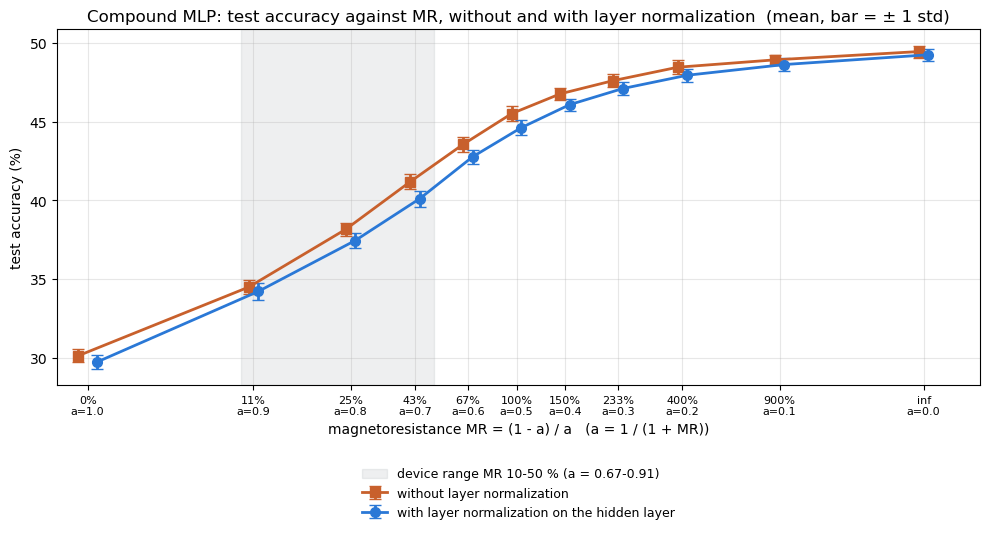

saved the plot: mlp_compound_MR_layernorm.png


In [8]:
#N7: RESULTS FOR EVERY a: without against with layer normalization. Every table and the plot show both a and the
#    magnetoresistance MR = (1 - a) / a. It reads RESULTS_FILE, so it also works after a restart (run N1 and N4 first)
#    and shows the a values finished so far.

import json
saved = json.load(open(RESULTS_FILE))
runs_of = saved['runs']                         # version -> a as text -> list of runs
A_DONE = sorted({k for ver in VERSIONS for k, rs in runs_of.get(ver, {}).items() if rs}, key=float)

def test_accs(ver, k):
    """test accuracy of every run (mean over the 20 problems) of this version at this a; [] if none yet"""
    return [np.mean(r['te_accs']) for r in runs_of.get(ver, {}).get(k, [])]

def mean_std(x):
    return f"{np.mean(x):6.2f}% ± {np.std(x):5.2f}%" if x else f"{'-':>16}"

def epochs(ver, k, field):
    e = [r[field] for r in runs_of.get(ver, {}).get(k, [])]
    return f"{np.mean(e):4.0f} ({min(e):3d}-{max(e):3d})" if e else f"{'-':>13}"

print(f"COMPOUND MLP ({INPUT_SIZE} -> {HIDDEN_SIZE} -> {CLASSES_PER}), SGD lr {saved['settings']['learning_rate']:.0e}, "
      f"momentum {saved['settings']['momentum']}, early stopping (patience {saved['settings']['patience']})")
print("MR:     magnetoresistance (1 - a) / a;   a = 1 / (1 + MR)")
print("no LN:  without layer normalization;   LN: with layer normalization on the hidden layer")
print("test:   the best weights of each run, tested once on the 500 test images per problem; mean ± std over the runs")
print("LN - no LN: difference of the mean test accuracies, in points")
header = (f"{'a':>4} {'MR':>5} | {'n':>3} {'test, no LN':>16} {'train':>7} {'best epoch':>13} | "
          f"{'n':>3} {'test, LN':>16} {'train':>7} {'best epoch':>13} | {'LN - no LN':>10}")
print(header)
print("-" * len(header))
plot = {ver: [] for ver in VERSIONS}
for k in A_DONE:
    v = float(k)
    row = f"{k:>4} {mr_text(v):>5} |"
    for ver in VERSIONS:
        te = test_accs(ver, k)
        tr = [r['tr_acc'] for r in runs_of.get(ver, {}).get(k, [])]
        tr_text = f"{np.mean(tr):6.2f}%" if tr else f"{'-':>7}"
        row += f" {len(te):3d} {mean_std(te)} {tr_text} {epochs(ver, k, 'best_epoch')} |"
        if te:
            plot[ver].append((v, np.mean(te), np.std(te)))
    t0_, t1_ = test_accs('no_ln', k), test_accs('ln', k)
    row += f" {np.mean(t1_) - np.mean(t0_):+10.2f}" if (t0_ and t1_) else f" {'-':>10}"
    print(row)

for ver, ver_name in VERSIONS.items():
    print(f"\ntest accuracy of every problem, {ver_name} (mean of the runs)")
    print(f"{'a':>4} {'MR':>5} " + " ".join(f"{'P' + str(i + 1):>5}" for i in range(NUM_PROBLEMS)))
    for k in A_DONE:
        rs = runs_of.get(ver, {}).get(k, [])
        if rs:
            print(f"{k:>4} {mr_text(float(k)):>5} " + " ".join(f"{x:5.1f}" for x in np.mean([r['te_accs'] for r in rs], axis=0)))

print("\nrange of the trained weights (the best weights, all 20 problems' built weights; mean over the runs)")
print(f"{'a':>4} {'MR':>5} {'ver':>5} | {'hidden min':>10} {'hidden max':>10} {'hidden std':>10} | "
      f"{'output min':>10} {'output max':>10} {'output std':>10}")
for k in A_DONE:
    for ver in VERSIONS:
        rs = runs_of.get(ver, {}).get(k, [])
        if rs:
            h = np.mean([r['w_range']['hid'] for r in rs], axis=0)
            o = np.mean([r['w_range']['out'] for r in rs], axis=0)
            print(f"{k:>4} {mr_text(float(k)):>5} {ver:>5} | {h[0]:10.4f} {h[1]:10.4f} {h[2]:10.4f} | "
                  f"{o[0]:10.4f} {o[1]:10.4f} {o[2]:10.4f}")

# ---- the plot: x = MR on a symmetric-log axis (0 to 10 % linear, above 10 % logarithmic), so MR = 0 (a = 1.0) fits;
#      a = 0 (MR infinite) is drawn at the far right and labelled "inf"; every tick shows MR and a.
#      orange = without layer normalization, blue = with; the two are moved slightly apart so their bars don't hide each other
MR_INF_X = 3000            # where a = 0 (MR infinite) is drawn: right of the largest finite MR (900 % at a = 0.1)

def mr_x(v):
    m = mr_percent(v)
    return MR_INF_X if math.isinf(m) else m

def nudge(x, side):
    return x + 0.6 * side if x < 10 else x * (1.04 ** side)

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.axvspan(10, 50, color='#5A6874', alpha=0.10, label='device range MR 10-50 % (a = 0.67-0.91)')
style = {'no_ln': dict(color='#C8602C', marker='s', side=-1), 'ln': dict(color='#2A78D6', marker='o', side=+1)}
for ver, ver_name in VERSIONS.items():
    if plot[ver]:
        xs, ys, es = zip(*sorted((mr_x(v), y, e) for v, y, e in plot[ver]))
        s = style[ver]
        ax.errorbar([nudge(x, s['side']) for x in xs], ys, yerr=es, color=s['color'], lw=2, marker=s['marker'], ms=7,
                    capsize=4, label=ver_name)
ticks = sorted(mr_x(float(k)) for k in A_DONE)
a_at = {mr_x(float(k)): float(k) for k in A_DONE}
ax.set_xscale('symlog', linthresh=10, linscale=0.5)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{mr_text(a_at[t])}\na={a_at[t]:.1f}" for t in ticks], fontsize=8)
ax.minorticks_off()
ax.set_xlim(-2, MR_INF_X * 1.6)
ax.set_xlabel('magnetoresistance MR = (1 - a) / a   (a = 1 / (1 + MR))')
ax.set_ylabel('test accuracy (%)')
ax.set_title('Compound MLP: test accuracy against MR, without and with layer normalization  (mean, bar = ± 1 std)')
ax.grid(alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig('mlp_compound_MR_layernorm.png', dpi=150)
plt.show()
print("saved the plot: mlp_compound_MR_layernorm.png")
